# Network Intrusion Detector using Machine Learning
**IBM SkillsBuild | Final Project**

## 1. Introduction and Problem Statement
Networks face constant attacks such as denial-of-service, probing, and unauthorized access. This project builds a **Scikit-learn** model that classifies network connections as **Normal** or **Anomaly (attack)** using the public **NSL-KDD** dataset.

**Goals**
1. Explore and clean the data
2. Train and compare several classifiers
3. Evaluate with metrics that matter for security (recall, false positives)
4. Save the final model for reuse

## 2. Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib, warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## 3. Load the Dataset
NSL-KDD files: `KDDTrain+.txt` and `KDDTest+.txt`.
The cell below tries to download them automatically. If that fails, it asks you to upload them manually.

In [2]:
import os
urls = {
    "KDDTrain+.txt": "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt",
    "KDDTest+.txt":  "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt",
}
for fname, url in urls.items():
    if not os.path.exists(fname):
        os.system(f'wget -q -O "{fname}" "{url}"')

ok = all(os.path.exists(f) and os.path.getsize(f) > 100000 for f in urls)
if not ok:
    from google.colab import files
    print("Auto-download failed. Please upload KDDTrain+.txt and KDDTest+.txt")
    files.upload()
print("Files ready:", [f for f in urls if os.path.exists(f)])

Files ready: ['KDDTrain+.txt', 'KDDTest+.txt']


In [3]:
cols = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
"wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
"root_shell","su_attempted","num_root","num_file_creations","num_shells",
"num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
"srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
"same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
"dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
"dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
"dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
"label","difficulty"]

train = pd.read_csv("KDDTrain+.txt", names=cols)
test  = pd.read_csv("KDDTest+.txt",  names=cols)
print("Train:", train.shape, "| Test:", test.shape)
train.head()

Train: (125973, 43) | Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 4. Exploratory Data Analysis (EDA)

In [4]:
print("Missing values (train):", train.isnull().sum().sum())
print("Duplicate rows (train):", train.duplicated().sum())
train.describe().T.head(10)

Missing values (train): 0
Duplicate rows (train): 0


,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.0,0.0,0.0,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.0,44.0,276.0,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.0,0.0,516.0,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.0,0.0,0.0,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.0,0.0,0.0,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.0,0.0,0.0,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.0,0.0,0.0,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.0,0.0,0.0,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.0,0.0,1.0,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.0,0.0,0.0,7.479000e+03


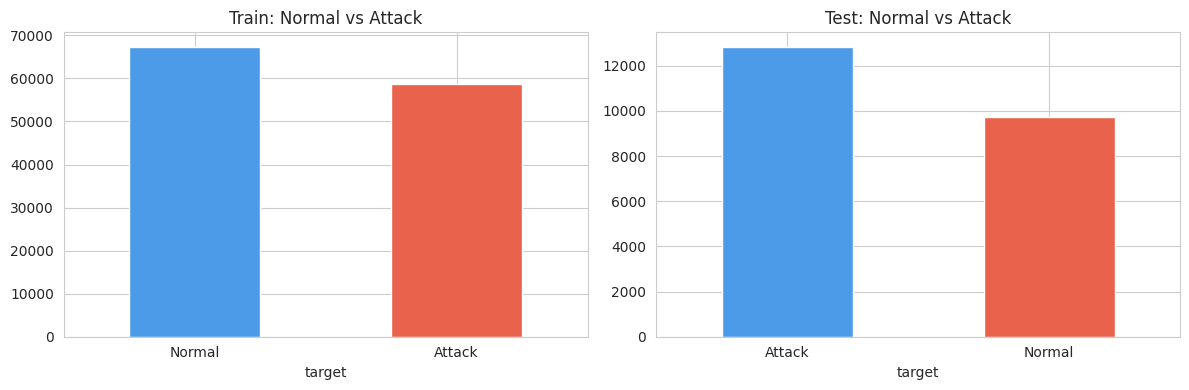

In [5]:
# Binary target: 0 = normal, 1 = attack
for df in (train, test):
    df.drop("difficulty", axis=1, inplace=True)
    df["target"] = (df["label"] != "normal").astype(int)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train["target"].map({0:"Normal",1:"Attack"}).value_counts().plot.bar(ax=ax[0], color=["#4c9be8","#e8624c"])
ax[0].set_title("Train: Normal vs Attack"); ax[0].tick_params(axis="x", rotation=0)
test["target"].map({0:"Normal",1:"Attack"}).value_counts().plot.bar(ax=ax[1], color=["#4c9be8","#e8624c"])
ax[1].set_title("Test: Normal vs Attack"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

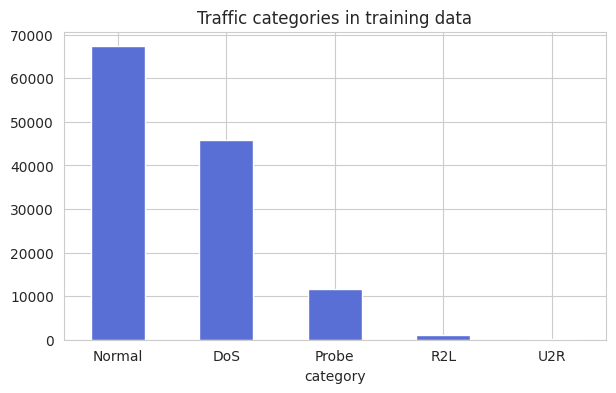

In [6]:
# Attack categories (DoS, Probe, R2L, U2R)
attack_map = {
 "normal":"Normal",
 **{a:"DoS"  for a in ["back","land","neptune","pod","smurf","teardrop","apache2","udpstorm","processtable","mailbomb"]},
 **{a:"Probe" for a in ["satan","ipsweep","nmap","portsweep","mscan","saint"]},
 **{a:"R2L"  for a in ["guess_passwd","ftp_write","imap","phf","multihop","warezmaster","warezclient","spy","xlock","xsnoop","snmpguess","snmpgetattack","httptunnel","sendmail","named"]},
 **{a:"U2R"  for a in ["buffer_overflow","loadmodule","rootkit","perl","sqlattack","xterm","ps"]},
}
train["category"] = train["label"].map(attack_map).fillna("Other")
plt.figure(figsize=(7,4))
train["category"].value_counts().plot.bar(color="#5a6fd6")
plt.title("Traffic categories in training data"); plt.xticks(rotation=0); plt.show()

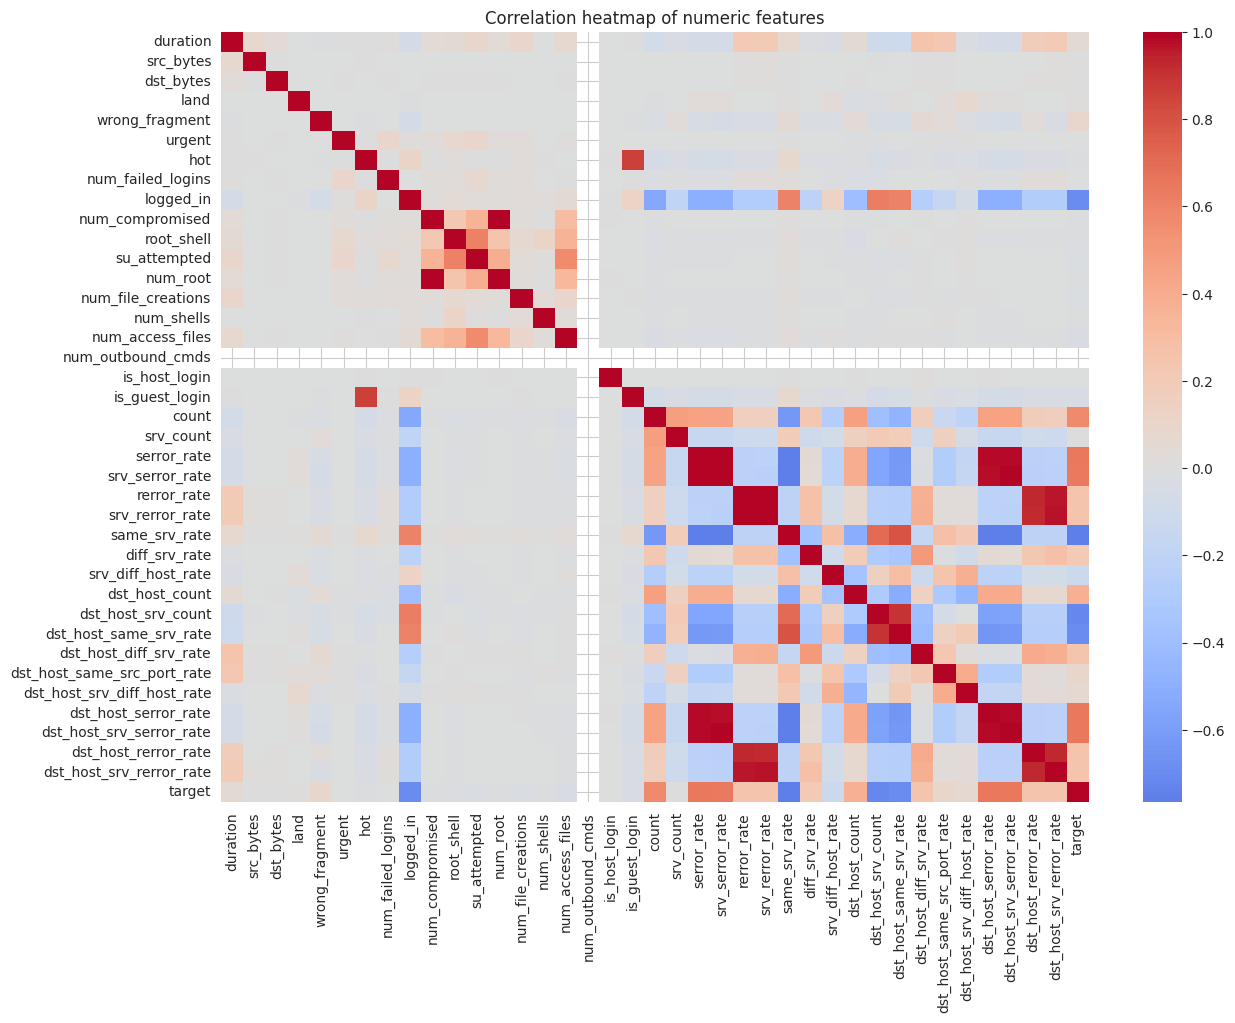

In [7]:
plt.figure(figsize=(14,10))
sns.heatmap(train.select_dtypes("number").corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric features"); plt.show()

## 5. Preprocessing
One-hot encode the categorical columns and scale the numeric ones, all inside a `Pipeline` to prevent data leakage.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

X_train = train.drop(["label","target","category"], axis=1); y_train = train["target"]
X_test  = test.drop(["label","target"], axis=1);             y_test  = test["target"]

cat = ["protocol_type","service","flag"]
num = [c for c in X_train.columns if c not in cat]

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ("num", StandardScaler(), num),
])

## 6. Train and Compare Models

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

results, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)])
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    fitted[name] = pipe
    results.append([name, accuracy_score(y_test,p), precision_score(y_test,p),
                    recall_score(y_test,p), f1_score(y_test,p)])

res = pd.DataFrame(results, columns=["Model","Accuracy","Precision","Recall","F1"]).set_index("Model")
res.round(4)

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.7536,0.9175,0.6232,0.7423
Decision Tree,0.8141,0.9598,0.7029,0.8115
Random Forest,0.7787,0.9689,0.6314,0.7646


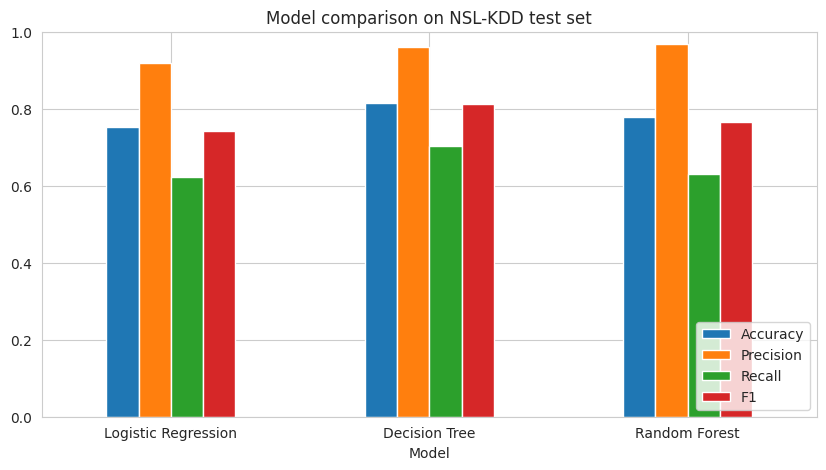

In [10]:
res.plot.bar(figsize=(10,5), rot=0)
plt.title("Model comparison on NSL-KDD test set"); plt.ylim(0,1); plt.legend(loc="lower right"); plt.show()

## 7. Detailed Evaluation of the Best Model

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

best_name = res["F1"].idxmax()
best = fitted[best_name]
pred = best.predict(X_test)
proba = best.predict_proba(X_test)[:,1]
print("Best model:", best_name)
print(classification_report(y_test, pred, target_names=["Normal","Attack"]))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))

Best model: Decision Tree
              precision    recall  f1-score   support

      Normal       0.71      0.96      0.82      9711
      Attack       0.96      0.70      0.81     12833

    accuracy                           0.81     22544
   macro avg       0.83      0.83      0.81     22544
weighted avg       0.85      0.81      0.81     22544

ROC-AUC: 0.8322


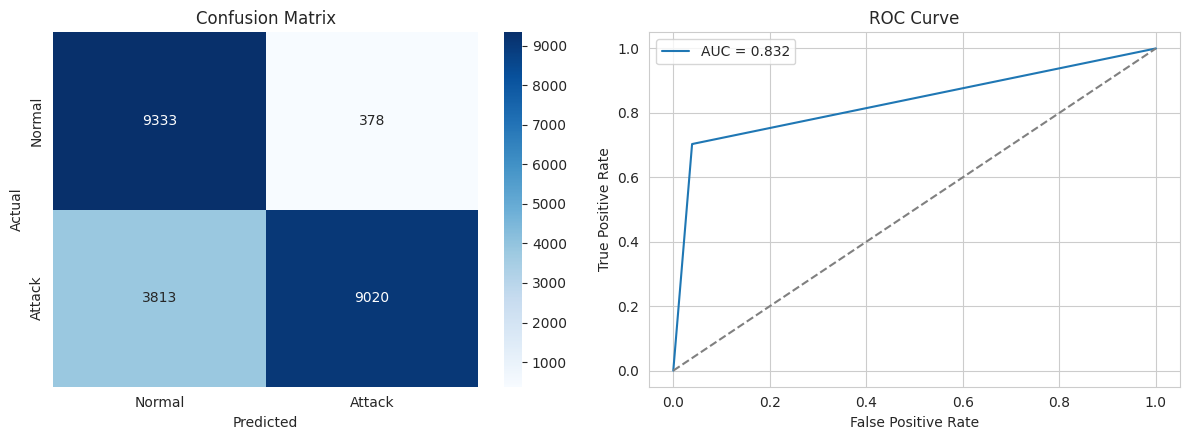

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Normal","Attack"], yticklabels=["Normal","Attack"])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Confusion Matrix")
fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
ax[1].plot([0,1],[0,1],"--",color="grey"); ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate"); ax[1].set_title("ROC Curve"); ax[1].legend()
plt.tight_layout(); plt.show()

**How to read this:** *Recall* shows how many real attacks were caught (missed attacks are dangerous). *Precision* shows how many alerts were real (low precision causes alert fatigue).

## 8. Improve the Model: Hyperparameter Tuning

In [13]:
from sklearn.model_selection import RandomizedSearchCV

pipe_rf = Pipeline([("pre", pre), ("model", RandomForestClassifier(n_jobs=-1, random_state=42))])
params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 15, 25],
    "model__min_samples_split": [2, 5, 10],
}
search = RandomizedSearchCV(pipe_rf, params, n_iter=8, cv=3, scoring="f1", n_jobs=-1, random_state=42)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)

tuned = search.best_estimator_
tp = tuned.predict(X_test)
print(f"Tuned RF -> Accuracy {accuracy_score(y_test,tp):.4f} | Recall {recall_score(y_test,tp):.4f} | F1 {f1_score(y_test,tp):.4f}")

Best params: {'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__max_depth': None}
Tuned RF -> Accuracy 0.7787 | Recall 0.6314 | F1 0.7646


## 9. Feature Importance

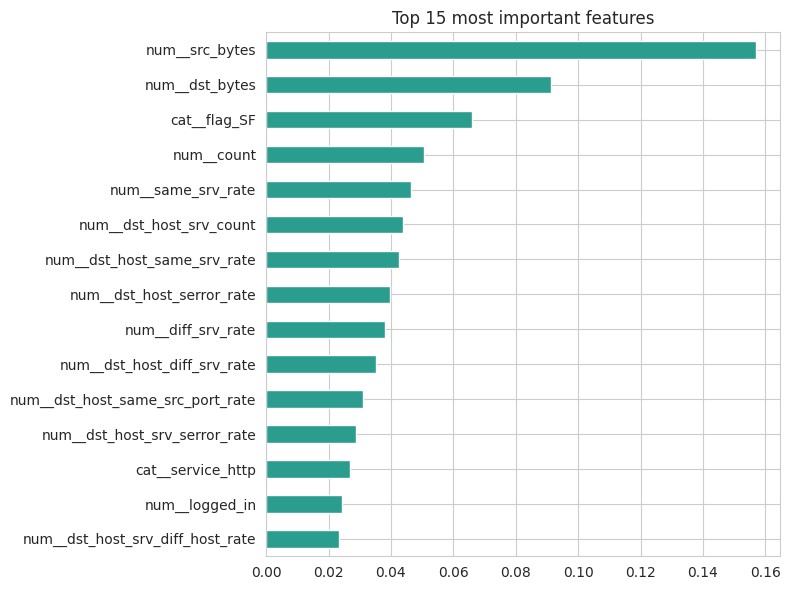

In [14]:
rf = tuned.named_steps["model"]
names = tuned.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=names).sort_values(ascending=False).head(15)
plt.figure(figsize=(8,6))
imp[::-1].plot.barh(color="#2a9d8f")
plt.title("Top 15 most important features"); plt.tight_layout(); plt.show()

## 10. Optional: Unsupervised Anomaly Detection (Isolation Forest)
Trained on **normal traffic only**, to see how a model with no attack labels performs.

In [15]:
from sklearn.ensemble import IsolationForest

Xn = pre.fit_transform(X_train[y_train==0])
iso = IsolationForest(n_estimators=200, contamination=0.1, random_state=42, n_jobs=-1).fit(Xn)
ip = (iso.predict(pre.transform(X_test)) == -1).astype(int)
print(classification_report(y_test, ip, target_names=["Normal","Attack"]))

              precision    recall  f1-score   support

      Normal       0.71      0.93      0.80      9711
      Attack       0.93      0.71      0.80     12833

    accuracy                           0.80     22544
   macro avg       0.82      0.82      0.80     22544
weighted avg       0.83      0.80      0.80     22544



## 11. Save the Model and Test a Prediction

In [16]:
joblib.dump(tuned, "intrusion_detector.pkl")

loaded = joblib.load("intrusion_detector.pkl")
sample = X_test.sample(5, random_state=1)
out = pd.DataFrame({"Predicted": np.where(loaded.predict(sample)==1,"Attack","Normal"),
                    "Actual": np.where(y_test.loc[sample.index]==1,"Attack","Normal")})
out

,Predicted,Actual
0,Normal,Attack
1,Attack,Attack
2,Normal,Normal
3,Normal,Normal
4,Normal,Attack


In [17]:
from google.colab import files
files.download("intrusion_detector.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusion
- Built an end-to-end Scikit-learn pipeline that detects network anomalies on NSL-KDD.
- Compared Logistic Regression, Decision Tree and Random Forest; Random Forest tuned with `RandomizedSearchCV` gave the best balance of recall and precision.
- Key features such as traffic volume (`src_bytes`, `dst_bytes`), connection counts and error rates were most informative.

**Limitations**
- NSL-KDD is old and does not reflect modern traffic.
- The test set contains attack types not seen in training, so accuracy is lower than on the training data. This is expected.
- Not tested on live packet streams.

**Future Work**
- Multi-class detection (DoS / Probe / R2L / U2R)
- Newer datasets such as UNB-NB15 or CIC-IDS2017
- Deep learning (LSTM / autoencoders) and real-time packet capture
- Deployment as an API or dashboard on IBM Cloud

## References
- NSL-KDD dataset, University of New Brunswick
- Scikit-learn documentation